In [1]:
import os
import pyspark

from pyspark.sql import SparkSession
from pyspark.sql.functions import *

In [2]:
print("Current Working Directory:")
print(os.getcwd())

print("\nAvailable Files:")
print(os.listdir())

Current Working Directory:
C:\Users\hp\Downloads\FlightScope

Available Files:
['.git', '.gitignore', '.ipynb_checkpoints', 'dataset', 'FlightScope.ipynb']


In [3]:
spark = SparkSession.builder \
    .appName("FlightScope") \
    .master("local[*]") \
    .getOrCreate()

print("Spark Session Created Successfully!")

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark Session Created Successfully!


In [4]:
print("PySpark Version:", pyspark.__version__)

PySpark Version: 4.3.0


In [5]:
flights_path = "dataset/flights.csv"

df = spark.read.csv(
    flights_path,
    header=True,
    inferSchema=True
)

print("Flight Dataset Loaded Successfully!")

Flight Dataset Loaded Successfully!


In [6]:
print("\nColumn Names:")
print(df.columns)


Column Names:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']


In [7]:
df.head

<bound method DataFrame.head of DataFrame[YEAR: int, MONTH: int, DAY: int, DAY_OF_WEEK: int, AIRLINE: string, FLIGHT_NUMBER: int, TAIL_NUMBER: string, ORIGIN_AIRPORT: string, DESTINATION_AIRPORT: string, SCHEDULED_DEPARTURE: int, DEPARTURE_TIME: int, DEPARTURE_DELAY: int, TAXI_OUT: int, WHEELS_OFF: int, SCHEDULED_TIME: int, ELAPSED_TIME: int, AIR_TIME: int, DISTANCE: int, WHEELS_ON: int, TAXI_IN: int, SCHEDULED_ARRIVAL: int, ARRIVAL_TIME: int, ARRIVAL_DELAY: int, DIVERTED: int, CANCELLED: int, CANCELLATION_REASON: string, AIR_SYSTEM_DELAY: int, SECURITY_DELAY: int, AIRLINE_DELAY: int, LATE_AIRCRAFT_DELAY: int, WEATHER_DELAY: int]>

In [8]:
print("Total Flight Records:", df.count())

Total Flight Records: 5819079


In [9]:
sample_df = df.orderBy(rand(seed=42)).limit(15000)

print("Sample Created Successfully!")
print("Total Sample Records:", sample_df.count())

Sample Created Successfully!
Total Sample Records: 15000


In [10]:
sample_pdf = sample_df.toPandas()

sample_pdf.to_csv(
    "dataset/flights_sample_15000.csv",
    index=False
)

print("Dataset saved successfully!")

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Dataset saved successfully!


In [11]:
flights = spark.read.csv(
    "dataset/flights_sample_15000.csv",
    header=True,
    inferSchema=True
)

print("Dataset Loaded Successfully!")
print("Total Records:", flights.count())

Dataset Loaded Successfully!
Total Records: 15000


In [13]:
flights.printSchema()
flights.show(5)

root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: double (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- SCHEDULED_TIME: integer (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: integer (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRIVAL_TIME: double (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = tru

In [15]:
## 1. Dataset Understanding and Exploration
##In this section, we will explore the flight dataset to understand its structure, columns, data types, and overall data quality.

In [12]:
print("Total Rows:", flights.count())
print("Total Columns:", len(flights.columns))

Total Rows: 15000
Total Columns: 31


In [13]:
print("Dataset Columns:")

for column in flights.columns:
    print(column)

Dataset Columns:
YEAR
MONTH
DAY
DAY_OF_WEEK
AIRLINE
FLIGHT_NUMBER
TAIL_NUMBER
ORIGIN_AIRPORT
DESTINATION_AIRPORT
SCHEDULED_DEPARTURE
DEPARTURE_TIME
DEPARTURE_DELAY
TAXI_OUT
WHEELS_OFF
SCHEDULED_TIME
ELAPSED_TIME
AIR_TIME
DISTANCE
WHEELS_ON
TAXI_IN
SCHEDULED_ARRIVAL
ARRIVAL_TIME
ARRIVAL_DELAY
DIVERTED
CANCELLED
CANCELLATION_REASON
AIR_SYSTEM_DELAY
SECURITY_DELAY
AIRLINE_DELAY
LATE_AIRCRAFT_DELAY
WEATHER_DELAY


In [14]:
flights.printSchema()

root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: double (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- SCHEDULED_TIME: integer (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: integer (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRIVAL_TIME: double (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = tru

In [15]:
flights.select(
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "DISTANCE",
    "AIR_TIME"
).describe().show(truncate=False)

+-------+-----------------+-----------------+-----------------+------------------+
|summary|DEPARTURE_DELAY  |ARRIVAL_DELAY    |DISTANCE         |AIR_TIME          |
+-------+-----------------+-----------------+-----------------+------------------+
|count  |14800            |14753            |15000            |14753             |
|mean   |9.590945945945945|4.723649427235139|830.5644         |114.42974310309768|
|stddev |36.58416803137372|39.22762491296174|614.8337468685287|72.98188617491299 |
|min    |-25.0            |-55.0            |31               |9.0               |
|max    |816.0            |813.0            |4983             |665.0             |
+-------+-----------------+-----------------+-----------------+------------------+



In [17]:
## 2. Data Preprocessing
##In this section, we will check the dataset for missing values and duplicate records and perform the necessary data cleaning operations using PySpark.

In [18]:
from pyspark.sql.functions import col, count, when

missing_values = flights.select(
    [count(when(col(c).isNull(), c)).alias(c)
     for c in flights.columns]
)

missing_values.show()

+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+--------+---------+-------+-----------------+------------+-------------+--------+---------+-------------------+----------------+--------------+-------------+-------------------+-------------+
|YEAR|MONTH|DAY|DAY_OF_WEEK|AIRLINE|FLIGHT_NUMBER|TAIL_NUMBER|ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|DEPARTURE_TIME|DEPARTURE_DELAY|TAXI_OUT|WHEELS_OFF|SCHEDULED_TIME|ELAPSED_TIME|AIR_TIME|DISTANCE|WHEELS_ON|TAXI_IN|SCHEDULED_ARRIVAL|ARRIVAL_TIME|ARRIVAL_DELAY|DIVERTED|CANCELLED|CANCELLATION_REASON|AIR_SYSTEM_DELAY|SECURITY_DELAY|AIRLINE_DELAY|LATE_AIRCRAFT_DELAY|WEATHER_DELAY|
+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+-

In [19]:
##duplicate records
total_records = flights.count()

unique_records = flights.dropDuplicates().count()

duplicate_records = total_records - unique_records

print("Total Records:", total_records)
print("Unique Records:", unique_records)
print("Duplicate Records:", duplicate_records)

Total Records: 15000
Unique Records: 15000
Duplicate Records: 0


In [20]:
flights.describe().show()

+-------+------+------------------+-----------------+------------------+-------+-----------------+-----------+------------------+-------------------+-------------------+------------------+-----------------+-----------------+------------------+------------------+-----------------+------------------+-----------------+------------------+-----------------+-----------------+------------------+-----------------+-------------------+--------------------+-------------------+------------------+-------------------+------------------+-------------------+------------------+
|summary|  YEAR|             MONTH|              DAY|       DAY_OF_WEEK|AIRLINE|    FLIGHT_NUMBER|TAIL_NUMBER|    ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|    DEPARTURE_TIME|  DEPARTURE_DELAY|         TAXI_OUT|        WHEELS_OFF|    SCHEDULED_TIME|     ELAPSED_TIME|          AIR_TIME|         DISTANCE|         WHEELS_ON|          TAXI_IN|SCHEDULED_ARRIVAL|      ARRIVAL_TIME|    ARRIVAL_DELAY|           DIVERTED|   

In [21]:
## missing value chcek 
from pyspark.sql.functions import col, count, when

missing_values = flights.select(
    [count(when(col(c).isNull(), c)).alias(c)
     for c in flights.columns]
)

missing_values.show()

+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+--------+---------+-------+-----------------+------------+-------------+--------+---------+-------------------+----------------+--------------+-------------+-------------------+-------------+
|YEAR|MONTH|DAY|DAY_OF_WEEK|AIRLINE|FLIGHT_NUMBER|TAIL_NUMBER|ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|DEPARTURE_TIME|DEPARTURE_DELAY|TAXI_OUT|WHEELS_OFF|SCHEDULED_TIME|ELAPSED_TIME|AIR_TIME|DISTANCE|WHEELS_ON|TAXI_IN|SCHEDULED_ARRIVAL|ARRIVAL_TIME|ARRIVAL_DELAY|DIVERTED|CANCELLED|CANCELLATION_REASON|AIR_SYSTEM_DELAY|SECURITY_DELAY|AIRLINE_DELAY|LATE_AIRCRAFT_DELAY|WEATHER_DELAY|
+----+-----+---+-----------+-------+-------------+-----------+--------------+-------------------+-------------------+--------------+---------------+--------+----------+--------------+------------+--------+-

In [22]:
##count of missing value 
import builtins

missing_values_list = missing_values.collect()[0]
total_missing = builtins.sum(missing_values_list)
print("Total Missing Values:", total_missing)

Total Missing Values: 78016


In [23]:
missing_values.select(
    "AIRLINE",
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "ORIGIN_AIRPORT",
    "DESTINATION_AIRPORT",
    "DISTANCE",
    "AIR_TIME"
).show()

+-------+---------------+-------------+--------------+-------------------+--------+--------+
|AIRLINE|DEPARTURE_DELAY|ARRIVAL_DELAY|ORIGIN_AIRPORT|DESTINATION_AIRPORT|DISTANCE|AIR_TIME|
+-------+---------------+-------------+--------------+-------------------+--------+--------+
|      0|            200|          247|             0|                  0|       0|     247|
+-------+---------------+-------------+--------------+-------------------+--------+--------+



In [24]:
flights = flights.dropDuplicates()

print("Records after removing duplicates:", flights.count())

Records after removing duplicates: 15000


In [25]:
flights.groupBy("CANCELLED").count().show()

+---------+-----+
|CANCELLED|count|
+---------+-----+
|        1|  211|
|        0|14789|
+---------+-----+



In [26]:
flights.filter(
    col("ARRIVAL_DELAY").isNull()
).select(
    "AIRLINE",
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "CANCELLED",
    "CANCELLATION_REASON"
).show(10)

+-------+---------------+-------------+---------+-------------------+
|AIRLINE|DEPARTURE_DELAY|ARRIVAL_DELAY|CANCELLED|CANCELLATION_REASON|
+-------+---------------+-------------+---------+-------------------+
|     MQ|           NULL|         NULL|        1|                  B|
|     WN|           NULL|         NULL|        1|                  A|
|     AA|          182.0|         NULL|        0|               NULL|
|     UA|           NULL|         NULL|        1|                  B|
|     OO|           NULL|         NULL|        1|                  A|
|     OO|           NULL|         NULL|        1|                  B|
|     OO|           NULL|         NULL|        1|                  B|
|     UA|           NULL|         NULL|        1|                  B|
|     MQ|           NULL|         NULL|        1|                  A|
|     MQ|           NULL|         NULL|        1|                  B|
+-------+---------------+-------------+---------+-------------------+
only showing top 10 

In [27]:
flights.filter(
    col("ARRIVAL_DELAY").isNull()
).groupBy("CANCELLED").count().show()

+---------+-----+
|CANCELLED|count|
+---------+-----+
|        1|  211|
|        0|   36|
+---------+-----+



In [28]:
completed_flights = flights.filter(
    (col("CANCELLED") == 0) &
    (col("ARRIVAL_DELAY").isNotNull())
)

print("Completed Flights:", completed_flights.count())

Completed Flights: 14753


In [29]:
## 3. Airline Performance Analysis
## In this section, we will analyze airline operations and compare their performance based on flight delays and punctuality.

In [30]:
operated_flights = flights.filter(
    col("CANCELLED") == 0
)
print("Total Operated Flights:", operated_flights.count())

Total Operated Flights: 14789


In [33]:
## Check airline-wise flight counts

operated_flights.groupBy("AIRLINE").count().show()

+-------+-----+
|AIRLINE|count|
+-------+-----+
|     UA| 1353|
|     NK|  313|
|     AA| 1816|
|     EV| 1416|
|     B6|  686|
|     DL| 2231|
|     OO| 1513|
|     F9|  230|
|     US|  476|
|     MQ|  701|
|     HA|  199|
|     AS|  436|
|     VX|  159|
|     WN| 3260|
+-------+-----+



In [35]:
### Number of Delayed Flights by Airline
#In this section, we will calculate the number of flights delayed by more than 15 minutes for each airline.

In [39]:
# delayed flight
delayed_flights = operated_flights.filter(
    col("ARRIVAL_DELAY") > 15
)

delayed_flights.groupBy("AIRLINE").count().show()

+-------+-----+
|AIRLINE|count|
+-------+-----+
|     UA|  284|
|     NK|  103|
|     AA|  326|
|     EV|  276|
|     B6|  168|
|     DL|  299|
|     OO|  273|
|     F9|   55|
|     US|   81|
|     MQ|  150|
|     HA|   34|
|     AS|   51|
|     VX|   31|
|     WN|  571|
+-------+-----+



In [43]:
# on-time performance success rate 
from pyspark.sql.functions import sum, when, round

airline_performance = operated_flights.groupBy("AIRLINE").agg(
    count("ARRIVAL_DELAY").alias("TOTAL_FLIGHTS"),
    sum(when(col("ARRIVAL_DELAY") > 15, 1).otherwise(0)).alias("DELAYED_FLIGHTS"),
    sum(when(col("ARRIVAL_DELAY") <= 15, 1).otherwise(0)).alias("ON_TIME_FLIGHTS")
)

airline_performance = airline_performance.withColumn(
    "ON_TIME_PERCENTAGE",
    round((col("ON_TIME_FLIGHTS") / col("TOTAL_FLIGHTS")) * 100, 2)
)

airline_performance.show()

+-------+-------------+---------------+---------------+------------------+
|AIRLINE|TOTAL_FLIGHTS|DELAYED_FLIGHTS|ON_TIME_FLIGHTS|ON_TIME_PERCENTAGE|
+-------+-------------+---------------+---------------+------------------+
|     UA|         1351|            284|           1067|             78.98|
|     NK|          313|            103|            210|             67.09|
|     AA|         1810|            326|           1484|             81.99|
|     EV|         1406|            276|           1130|             80.37|
|     B6|          683|            168|            515|              75.4|
|     DL|         2227|            299|           1928|             86.57|
|     OO|         1510|            273|           1237|             81.92|
|     F9|          230|             55|            175|             76.09|
|     US|          476|             81|            395|             82.98|
|     MQ|          699|            150|            549|             78.54|
|     HA|          199|  

In [44]:
### 3.3 Average Arrival Delay by Airline
## In this section, we will calculate the average arrival delay for each airline to compare their punctuality. 

In [48]:
## Average Arrival Delay
from pyspark.sql.functions import avg, round

average_delay = operated_flights.groupBy("AIRLINE").agg(
    round(avg("ARRIVAL_DELAY"), 2).alias("AVERAGE_ARRIVAL_DELAY")
)

average_delay.orderBy("AVERAGE_ARRIVAL_DELAY").show()

print("Best Performing Airlines:")
average_delay.orderBy("AVERAGE_ARRIVAL_DELAY").show(3)

print("Worst Performing Airlines:")
average_delay.orderBy("AVERAGE_ARRIVAL_DELAY", ascending=False).show(3)

+-------+---------------------+
|AIRLINE|AVERAGE_ARRIVAL_DELAY|
+-------+---------------------+
|     AS|                -0.43|
|     DL|                 1.09|
|     US|                 1.83|
|     AA|                  3.7|
|     WN|                 4.08|
|     HA|                 4.48|
|     OO|                 5.48|
|     EV|                 6.08|
|     UA|                 6.88|
|     VX|                 7.31|
|     MQ|                 7.86|
|     B6|                 7.92|
|     F9|                10.16|
|     NK|                16.57|
+-------+---------------------+

Best Performing Airlines:
+-------+---------------------+
|AIRLINE|AVERAGE_ARRIVAL_DELAY|
+-------+---------------------+
|     AS|                -0.43|
|     DL|                 1.09|
|     US|                 1.83|
+-------+---------------------+
only showing top 3 rows
Worst Performing Airlines:
+-------+---------------------+
|AIRLINE|AVERAGE_ARRIVAL_DELAY|
+-------+---------------------+
|     NK|                1

In [49]:
## Data Visualization

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


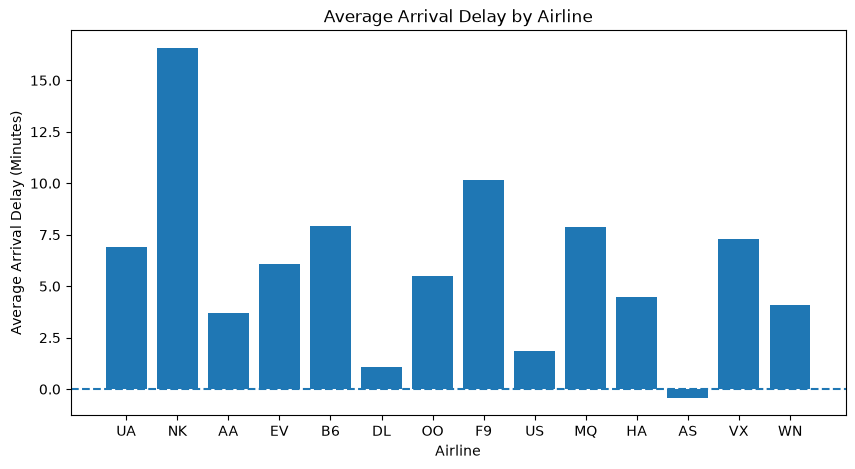

In [51]:
### 4.1 Average Arrival Delay by Airline

import matplotlib.pyplot as plt

average_pdf = average_delay.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    average_pdf["AIRLINE"],
    average_pdf["AVERAGE_ARRIVAL_DELAY"]
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.title("Average Arrival Delay by Airline")

plt.show()

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


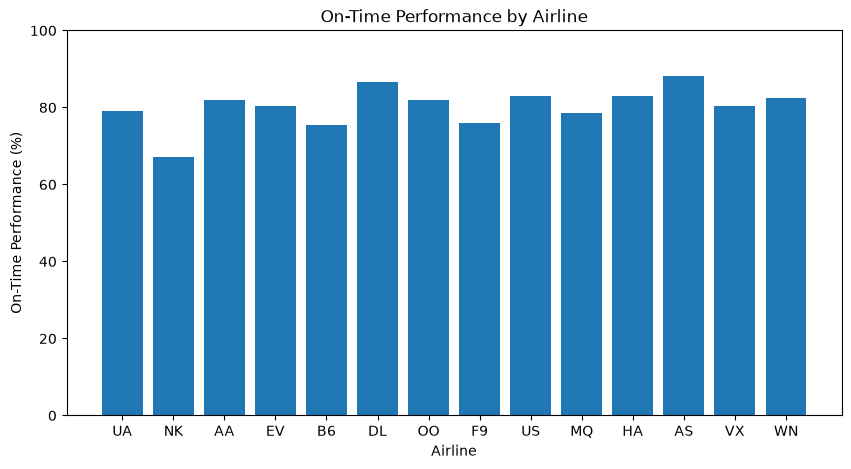

In [52]:
### 4.2 On-Time Performance by Airline

performance_pdf = airline_performance.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    performance_pdf["AIRLINE"],
    performance_pdf["ON_TIME_PERCENTAGE"]
)

plt.xlabel("Airline")
plt.ylabel("On-Time Performance (%)")
plt.title("On-Time Performance by Airline")

plt.ylim(0, 100)

plt.show()

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


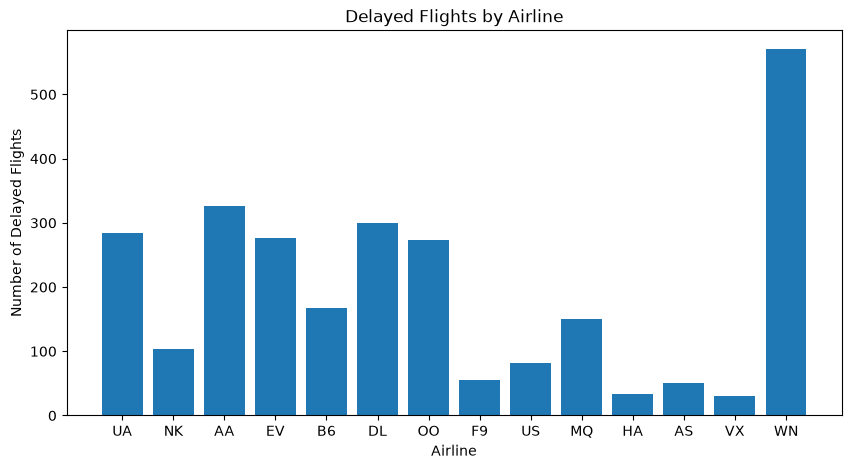

In [53]:
### 4.3 Delayed Flights by Airline

delayed_count = delayed_flights.groupBy("AIRLINE").count()

delayed_pdf = delayed_count.toPandas()

plt.figure(figsize=(10, 5))

plt.bar(
    delayed_pdf["AIRLINE"],
    delayed_pdf["count"]
)

plt.xlabel("Airline")
plt.ylabel("Number of Delayed Flights")
plt.title("Delayed Flights by Airline")

plt.show()

C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


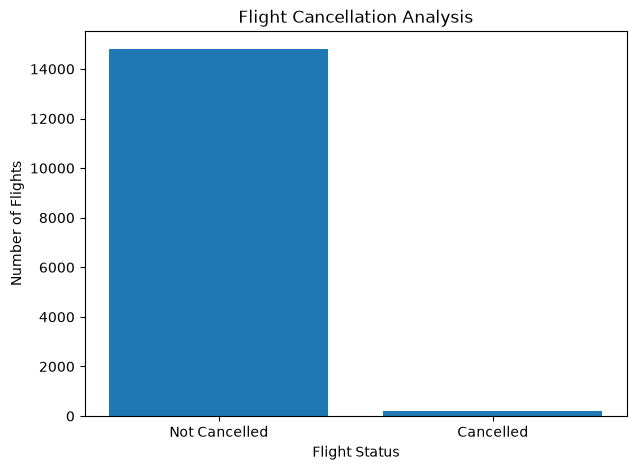

In [55]:
## 4.5 – Flight Cancellation Analysis.

cancellation_data = flights.groupBy("CANCELLED").count().toPandas()

labels = ["Not Cancelled", "Cancelled"]

plt.figure(figsize=(7, 5))
plt.bar(labels, cancellation_data.sort_values("CANCELLED")["count"])

plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")
plt.title("Flight Cancellation Analysis")

plt.show()

In [57]:
## Airport Performance Analysis.
origin_airport_count = flights.groupBy("ORIGIN_AIRPORT").count()

top_airports = origin_airport_count.orderBy(
    "count", ascending=False
).limit(10)

top_airports.show()

+--------------+-----+
|ORIGIN_AIRPORT|count|
+--------------+-----+
|           ATL|  872|
|           ORD|  733|
|           DFW|  608|
|           DEN|  518|
|           LAX|  494|
|           PHX|  400|
|           IAH|  385|
|           SFO|  359|
|           LAS|  358|
|           MCO|  288|
+--------------+-----+



C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


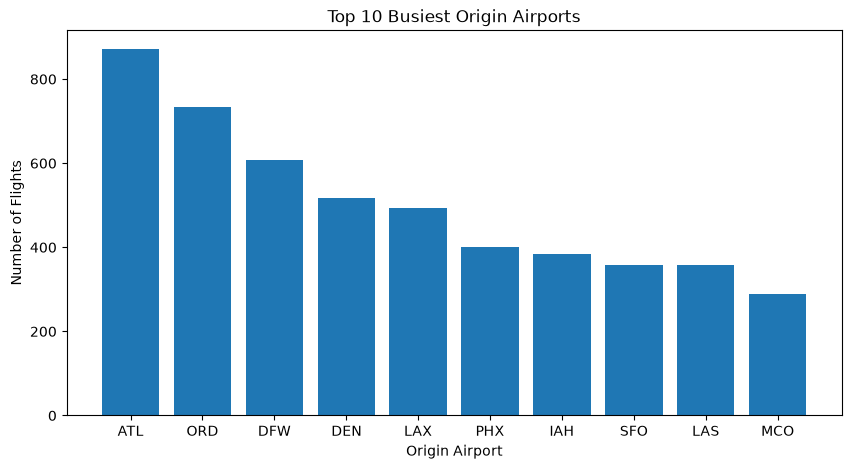

In [58]:
airport_pdf = top_airports.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(airport_pdf["ORIGIN_AIRPORT"], airport_pdf["count"])

plt.xlabel("Origin Airport")
plt.ylabel("Number of Flights")
plt.title("Top 10 Busiest Origin Airports")

plt.show()

In [60]:
## Average Arrival Delay by Airport
from pyspark.sql.functions import avg, round

airport_delay = flights.filter(
    (col("CANCELLED") == 0) & (col("ARRIVAL_DELAY").isNotNull())
)

average_airport_delay = airport_delay.groupBy("ORIGIN_AIRPORT").agg(
    round(avg("ARRIVAL_DELAY"), 2).alias("AVERAGE_DELAY")
)

top_delayed_airports = average_airport_delay.orderBy(
    "AVERAGE_DELAY", ascending=False
).limit(10)

top_delayed_airports.show()

+--------------+-------------+
|ORIGIN_AIRPORT|AVERAGE_DELAY|
+--------------+-------------+
|           FAI|       197.67|
|           MKG|        130.0|
|           BQN|        124.0|
|           LCH|        123.0|
|         11986|        117.0|
|           IAG|         72.0|
|           COU|        65.75|
|         14252|         60.0|
|           PSG|         57.6|
|         15624|         55.0|
+--------------+-------------+



In [62]:
from pyspark.sql.functions import avg, round

distance_delay = flights.filter(
    (col("CANCELLED") == 0) & (col("ARRIVAL_DELAY").isNotNull())
)

distance_analysis = distance_delay.groupBy("DISTANCE").agg(
    round(avg("ARRIVAL_DELAY"), 2).alias("AVERAGE_DELAY")
)

distance_analysis.orderBy("DISTANCE").show(10)

+--------+-------------+
|DISTANCE|AVERAGE_DELAY|
+--------+-------------+
|      31|          9.0|
|      41|         66.0|
|      67|        10.73|
|      68|        15.75|
|      69|         0.67|
|      73|        22.46|
|      74|        -9.78|
|      76|         -4.0|
|      77|       -11.83|
|      82|         -1.0|
+--------+-------------+
only showing top 10 rows


C:\Users\hp\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


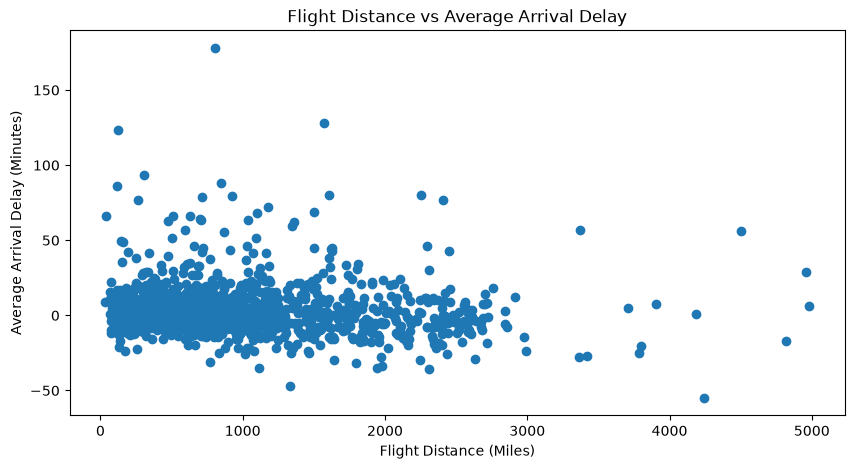

In [67]:
## Flight Distance vs Arrival Delay Analysis.
distance_pdf = distance_analysis.toPandas()

plt.figure(figsize=(10, 5))
plt.scatter(
    distance_pdf["DISTANCE"],
    distance_pdf["AVERAGE_DELAY"]
)

plt.xlabel("Flight Distance (Miles)")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.title("Flight Distance vs Average Arrival Delay")

plt.show()

In [70]:
## Departure Delay vs Arrival Delay Analysis.

departure_analysis = flights.filter(
    (col("CANCELLED") == 0) &
    (col("DEPARTURE_DELAY").isNotNull()) &
    (col("ARRIVAL_DELAY").isNotNull())
)

departure_analysis.select(
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY"
).show(10)

+---------------+-------------+
|DEPARTURE_DELAY|ARRIVAL_DELAY|
+---------------+-------------+
|           -4.0|        -15.0|
|           46.0|         52.0|
|           48.0|         40.0|
|            3.0|         15.0|
|           -1.0|          5.0|
|           27.0|         13.0|
|           17.0|          5.0|
|           -5.0|        -17.0|
|            1.0|        -11.0|
|           -6.0|        -11.0|
+---------------+-------------+
only showing top 10 rows


In [71]:
flights.createOrReplaceTempView("flights")

In [72]:
airline_sql = spark.sql("""
    SELECT
        AIRLINE,
        COUNT(*) AS TOTAL_FLIGHTS,
        ROUND(AVG(ARRIVAL_DELAY), 2) AS AVERAGE_DELAY
    FROM flights
    WHERE CANCELLED = 0
        AND ARRIVAL_DELAY IS NOT NULL
    GROUP BY AIRLINE
    ORDER BY AVERAGE_DELAY DESC
    LIMIT 10
""")

airline_sql.show()

+-------+-------------+-------------+
|AIRLINE|TOTAL_FLIGHTS|AVERAGE_DELAY|
+-------+-------------+-------------+
|     NK|          313|        16.57|
|     F9|          230|        10.16|
|     B6|          683|         7.92|
|     MQ|          699|         7.86|
|     VX|          159|         7.31|
|     UA|         1351|         6.88|
|     EV|         1406|         6.08|
|     OO|         1510|         5.48|
|     HA|          199|         4.48|
|     WN|         3255|         4.08|
+-------+-------------+-------------+



In [73]:
cancellation_sql = spark.sql("""
    SELECT
        AIRLINE,
        COUNT(*) AS TOTAL_FLIGHTS,
        SUM(CANCELLED) AS CANCELLED_FLIGHTS
    FROM flights
    GROUP BY AIRLINE
    ORDER BY CANCELLED_FLIGHTS DESC
""")

cancellation_sql.show()

+-------+-------------+-----------------+
|AIRLINE|TOTAL_FLIGHTS|CANCELLED_FLIGHTS|
+-------+-------------+-----------------+
|     EV|         1452|               36|
|     MQ|          737|               36|
|     WN|         3296|               36|
|     AA|         1847|               31|
|     OO|         1535|               22|
|     B6|          699|               13|
|     DL|         2243|               12|
|     UA|         1362|                9|
|     US|          485|                9|
|     NK|          318|                5|
|     AS|          438|                2|
|     F9|          230|                0|
|     HA|          199|                0|
|     VX|          159|                0|
+-------+-------------+-----------------+



In [74]:
from pyspark.sql.functions import when, col

ml_data = flights.filter(
    (col("CANCELLED") == 0) &
    (col("ARRIVAL_DELAY").isNotNull())
)

ml_data = ml_data.withColumn(
    "DELAYED",
    when(col("ARRIVAL_DELAY") > 15, 1).otherwise(0)
)

ml_data.select(
    "AIRLINE", "MONTH", "DAY_OF_WEEK",
    "DISTANCE", "SCHEDULED_DEPARTURE", "DELAYED"
).show(5)

+-------+-----+-----------+--------+-------------------+-------+
|AIRLINE|MONTH|DAY_OF_WEEK|DISTANCE|SCHEDULED_DEPARTURE|DELAYED|
+-------+-----+-----------+--------+-------------------+-------+
|     DL|    6|          4|    1589|                805|      0|
|     WN|    8|          4|     468|                735|      1|
|     EV|    1|          1|     429|               1824|      1|
|     WN|    8|          5|     580|               1455|      0|
|     DL|   12|          2|    1487|               1005|      0|
+-------+-----+-----------+--------+-------------------+-------+
only showing top 5 rows


In [75]:
from pyspark.ml.feature import StringIndexer

indexer = StringIndexer(
    inputCol="AIRLINE",
    outputCol="AIRLINE_INDEX",
    handleInvalid="keep"
)

indexer_model = indexer.fit(ml_data)
ml_data = indexer_model.transform(ml_data)

In [76]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=[
        "AIRLINE_INDEX",
        "MONTH",
        "DAY_OF_WEEK",
        "DISTANCE",
        "SCHEDULED_DEPARTURE"
    ],
    outputCol="features"
)

final_data = assembler.transform(ml_data)

In [77]:
train_data, test_data = final_data.randomSplit(
    [0.8, 0.2], seed=42
)

print("Training Records:", train_data.count())
print("Testing Records:", test_data.count())

Training Records: 11862
Testing Records: 2891


In [78]:
from pyspark.ml.classification import DecisionTreeClassifier

dt = DecisionTreeClassifier(
    labelCol="DELAYED",
    featuresCol="features",
    maxDepth=5
)

model = dt.fit(train_data)

predictions = model.transform(test_data)

predictions.select(
    "DELAYED", "prediction"
).show(10)

+-------+----------+
|DELAYED|prediction|
+-------+----------+
|      1|       0.0|
|      1|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
|      0|       0.0|
+-------+----------+
only showing top 10 rows


In [81]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

evaluator = MulticlassClassificationEvaluator(
    labelCol="DELAYED",
    predictionCol="prediction",
    metricName="accuracy"
)

accuracy = evaluator.evaluate(predictions)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 80.66%
